In [486]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [487]:
df = pd.read_csv("datas/dermatology_database_1.csv")

# Erythemato-Squamous Hastalıklar Veri Seti (Dermatology)

Bu veri seti, birbirine klinik ve histopatolojik olarak çok benzeyen 6 farklı cildiye hastalığının teşhisi için kullanılır.

* **Sınıflandırma Mantığı:** `0` (Yok), `1-2` (Orta), `3` (En yüksek derece).
* **İstisnalar:** `family_history` (0/1), `age` (Sayısal yaş / eksik veriler `?` ile gösterilmiştir).

---

## 1. Klinik Özellikler (Clinical)
Hastanın fiziki muayene bulgularıdır:

* **erythema:** Ciltteki kızarıklık derecesi.
* **scaling:** Pullanma / kepeklenme.
* **definite_borders:** Döküntü kenarlarının belirginliği.
* **itching:** Kaşıntı şiddeti.
* **koebner_phenomenon:** Çizik/travma sonrası lezyon oluşumu.
* **polygonal_papules:** Çokgen şekilli kabartılar.
* **follicular_papules:** Kıl kökleri etrafındaki kabartılar.
* **oral_mucosal_involvement:** Ağız içi mukoza tutulumu.
* **knee_and_elbow_involvement:** Diz ve dirsek tutulumu (Sedef belirtisi).
* **scalp_involvement:** Saçlı deri tutulumu.
* **family_history:** Ailede hastalık öyküsü (1: Var, 0: Yok).
* **age:** Hastanın yaşı.

---

## 2. Histopatolojik Özellikler (Histopathological)
Mikroskop altındaki biyopsi bulgularıdır:

* **melanin_incontinence:** Melanin pigmentinin dermise sızması.
* **eosinophils_in_infiltrate:** İnfiltratta eozinofil hücre varlığı.
* **pnl_infiltrate:** PNL (nötrofil) iltihap hücresi yoğunluğu.
* **fibrosis_papillary_dermis:** Papiller dermiste bağ dokusu artışı.
* **exocytosis:** İltihap hücrelerinin epidermise göçü.
* **acanthosis:** Epidermis katmanının kalınlaşması.
* **hyperkeratosis:** Cildin en dış tabakasının kalınlaşması.
* **parakeratosis:** Tam olgunlaşmamış keratinleşme (çekirdekli hücreler).
* **clubbing_rete_ridges:** Epidermis uzantılarında çomaklaşma.
* **elongation_rete_ridges:** Epidermis uzantılarında derinlemesine uzama.
* **thinning_suprapapillary_epidermis:** Dermal papilla üstündeki epidermiste incelme.
* **spongiform_pustule:** Epidermiste süngerimsi irinli boşluklar.
* **munro_microabcess:** Cilt altında mikro apse (nötrofil) birikimi.
* **focal_hypergranulosis:** Granüler tabakanın bölgesel kalınlaşması.
* **disappearance_granular_layer:** Granüler tabakanın kaybolması.
* **vacuolisation_damage_basal_layer:** Bazal tabakada hücresel boşluklanma/hasar.
* **spongiosis:** Epidermiste hücreler arası ödem (sıvı birikimi).
* **saw_tooth_appearance_retes:** Uzantılarda testere dişi görünümü (Liken Planus belirtisi).
* **follicular_horn_plug:** Kıl kökü ağzında keratin tıkacı.
* **perifollicular_parakeratosis:** Kıl kökü çevresinde parakeratoz.
* **inflammatory_mononuclear_infiltrate:** Mononükleer iltihap hücresi birikimi.
* **band_like_infiltrate:** Dermiste bant şeklinde yatay iltihap birikimi.

---

## 3. Hedef Sınıf (Class)

* **1:** Psoriasis (Sedef Hastalığı)
* **2:** Seborrheic Dermatitis (Seboreik Dermatit)
* **3:** Lichen Planus (Liken Planus)
* **4:** Pityriasis Rosea (Gül Hastalığı)
* **5:** Chronic Dermatitis (Kronik Dermatit)
* **6:** Pityriasis Rubra Pilaris

In [488]:
df.sample(5)

,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,disappearance_granular_layer,vacuolisation_damage_basal_layer,spongiosis,saw_tooth_appearance_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_mononuclear_infiltrate,band_like_infiltrate,age,class
274,1,2,2,1,1,0,0,0,2,2,...,2,0,0,0,0,0,2,0,62,1
223,2,1,2,2,0,0,0,0,0,0,...,0,0,2,0,0,0,1,0,25,5
177,2,2,0,3,0,0,0,0,0,0,...,0,0,2,0,0,0,2,0,40,2
135,1,1,1,1,1,0,1,0,2,3,...,0,0,0,0,0,0,3,0,25,1
211,2,3,2,0,0,0,0,0,3,2,...,0,0,0,0,0,0,1,0,70,1


In [489]:
df.columns

Index(['erythema', 'scaling', 'definite_borders', 'itching',
       'koebner_phenomenon', 'polygonal_papules', 'follicular_papules',
       'oral_mucosal_involvement', 'knee_and_elbow_involvement',
       'scalp_involvement', 'family_history', 'melanin_incontinence',
       'eosinophils_infiltrate', 'PNL_infiltrate', 'fibrosis_papillary_dermis',
       'exocytosis', 'acanthosis', 'hyperkeratosis', 'parakeratosis',
       'clubbing_rete_ridges', 'elongation_rete_ridges',
       'thinning_suprapapillary_epidermis', 'spongiform_pustule',
       'munro_microabcess', 'focal_hypergranulosis',
       'disappearance_granular_layer', 'vacuolisation_damage_basal_layer',
       'spongiosis', 'saw_tooth_appearance_retes', 'follicular_horn_plug',
       'perifollicular_parakeratosis', 'inflammatory_mononuclear_infiltrate',
       'band_like_infiltrate', 'age', 'class'],
      dtype='str')

### Veriyi Ön-İşleme

In [490]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 366 entries, 0 to 365
Data columns (total 35 columns):
 #   Column                               Non-Null Count  Dtype
---  ------                               --------------  -----
 0   erythema                             366 non-null    int64
 1   scaling                              366 non-null    int64
 2   definite_borders                     366 non-null    int64
 3   itching                              366 non-null    int64
 4   koebner_phenomenon                   366 non-null    int64
 5   polygonal_papules                    366 non-null    int64
 6   follicular_papules                   366 non-null    int64
 7   oral_mucosal_involvement             366 non-null    int64
 8   knee_and_elbow_involvement           366 non-null    int64
 9   scalp_involvement                    366 non-null    int64
 10  family_history                       366 non-null    int64
 11  melanin_incontinence                 366 non-null    int64
 12  eosin

In [491]:
df["age"] = df["age"].replace("?", np.nan)
df["age"] = df["age"].astype(float)
df["age"] = df["age"].fillna(df["age"].median(), inplace=True)

C:\Users\adigu\AppData\Local\Temp\ipykernel_20244\2302799272.py:3: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df["age"] = df["age"].fillna(df["age"].median(), inplace=True)


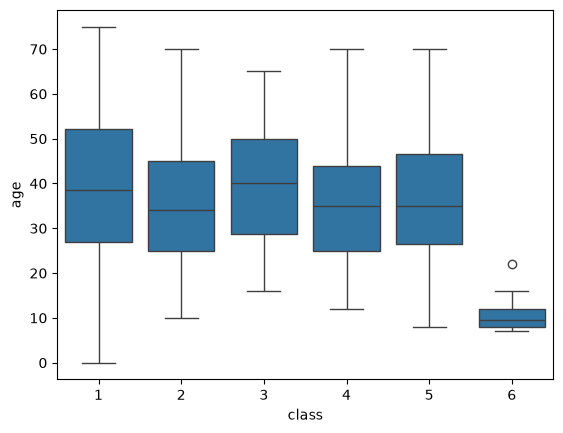

In [492]:
sns.boxplot(data=df, x="class", y="age")
plt.show()

### Train - Test Split ve Veri Çoğaltma

In [493]:
columns = ['erythema', 'scaling', 'definite_borders', 'itching',
       'koebner_phenomenon', 'polygonal_papules', 'follicular_papules',
       'oral_mucosal_involvement', 'knee_and_elbow_involvement',
       'scalp_involvement', 'family_history', 'melanin_incontinence',
       'eosinophils_infiltrate', 'PNL_infiltrate', 'fibrosis_papillary_dermis',
       'exocytosis', 'acanthosis', 'hyperkeratosis', 'parakeratosis',
       'clubbing_rete_ridges', 'elongation_rete_ridges',
       'thinning_suprapapillary_epidermis', 'spongiform_pustule',
       'munro_microabcess', 'focal_hypergranulosis',
       'disappearance_granular_layer', 'vacuolisation_damage_basal_layer',
       'spongiosis', 'saw_tooth_appearance_retes', 'follicular_horn_plug',
       'perifollicular_parakeratosis', 'inflammatory_mononuclear_infiltrate',
       'band_like_infiltrate', 'age', 'class']
       
X = df[columns[:-1]].values
y = df[columns[-1]].values

In [494]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.3, random_state=42)

In [495]:
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)

y_train = torch.tensor(y_train, dtype=torch.long).squeeze() - 1
y_test = torch.tensor(y_test, dtype=torch.long).squeeze() -1 

In [496]:
y_train

tensor([5, 1, 2, 4, 4, 4, 1, 2, 3, 1, 0, 3, 1, 2, 1, 0, 0, 2, 0, 0, 0, 1, 2, 2,
        4, 0, 2, 0, 3, 1, 1, 0, 0, 0, 4, 0, 2, 1, 4, 0, 0, 1, 2, 1, 4, 4, 4, 2,
        1, 2, 5, 3, 5, 2, 0, 3, 1, 1, 2, 0, 5, 1, 0, 0, 1, 1, 2, 3, 3, 3, 2, 1,
        5, 0, 4, 2, 0, 4, 2, 4, 0, 2, 3, 1, 3, 2, 4, 1, 0, 2, 4, 0, 2, 2, 1, 3,
        0, 0, 2, 3, 4, 2, 1, 3, 0, 2, 4, 4, 5, 5, 4, 0, 2, 0, 0, 1, 1, 1, 1, 1,
        1, 2, 0, 5, 1, 4, 3, 0, 0, 3, 0, 3, 2, 2, 4, 0, 3, 3, 1, 0, 3, 5, 0, 0,
        0, 0, 2, 3, 2, 1, 4, 4, 2, 0, 0, 2, 0, 5, 0, 5, 4, 3, 4, 1, 1, 3, 2, 0,
        2, 4, 0, 4, 3, 1, 2, 1, 1, 0, 4, 2, 3, 2, 0, 0, 2, 4, 4, 2, 0, 4, 3, 4,
        1, 1, 2, 2, 3, 0, 0, 0, 2, 0, 0, 3, 4, 1, 0, 4, 0, 0, 2, 0, 0, 0, 1, 4,
        3, 0, 0, 0, 4, 2, 2, 0, 2, 1, 2, 3, 1, 0, 2, 1, 2, 3, 0, 2, 0, 5, 3, 3,
        1, 0, 0, 5, 2, 0, 2, 4, 0, 5, 1, 5, 3, 3, 5, 0])

In [497]:
import torch.nn as nn

class DermatologyClassificationModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.layer = nn.Sequential(
            nn.Linear(34, 64),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(64, 6),
        )

    def forward(self, x : torch.Tensor) -> torch.Tensor:
        return self.layer(x)

In [498]:
model = DermatologyClassificationModel()

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

In [499]:
from torchmetrics.classification import MulticlassAccuracy

accuracy = MulticlassAccuracy(num_classes=6)

In [500]:
epochs = 120


for epoch in range(epochs):
    model.train()

    logits = model(X_train)
    loss = loss_fn(logits, y_train)

    pred = torch.softmax(logits, dim=1).argmax(dim=1)
    acc = accuracy(pred, y_train).item() * 100

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    model.eval()
    with torch.inference_mode():
        test_logits = model(X_test)
        test_loss = loss_fn(test_logits, y_test)

        test_pred = torch.softmax(test_logits, dim=1).argmax(dim=1)
        test_acc = accuracy(test_pred, y_test).item() * 100

    if epoch % 10 == 0:
        print(f"Epoch: {epoch} | Loss: {loss:.5f} | Accuracy: {acc:.2f}% | Test Loss: {test_loss:.5f} | Test Accuracy: {test_acc:.2f}%")

Epoch: 0 | Loss: 1.83668 | Accuracy: 13.86% | Test Loss: 2.38621 | Test Accuracy: 16.67%


Epoch: 10 | Loss: 0.68448 | Accuracy: 77.22% | Test Loss: 0.53720 | Test Accuracy: 83.33%
Epoch: 20 | Loss: 0.19592 | Accuracy: 90.02% | Test Loss: 0.11181 | Test Accuracy: 97.85%
Epoch: 30 | Loss: 0.08931 | Accuracy: 95.10% | Test Loss: 0.06995 | Test Accuracy: 95.63%
Epoch: 40 | Loss: 0.05418 | Accuracy: 96.58% | Test Loss: 0.06151 | Test Accuracy: 95.63%
Epoch: 50 | Loss: 0.01783 | Accuracy: 99.51% | Test Loss: 0.06897 | Test Accuracy: 95.63%
Epoch: 60 | Loss: 0.01933 | Accuracy: 100.00% | Test Loss: 0.06202 | Test Accuracy: 96.74%
Epoch: 70 | Loss: 0.01604 | Accuracy: 99.63% | Test Loss: 0.07111 | Test Accuracy: 97.85%
Epoch: 80 | Loss: 0.00831 | Accuracy: 99.51% | Test Loss: 0.09938 | Test Accuracy: 95.63%
Epoch: 90 | Loss: 0.01125 | Accuracy: 99.63% | Test Loss: 0.08472 | Test Accuracy: 97.85%
Epoch: 100 | Loss: 0.00825 | Accuracy: 99.63% | Test Loss: 0.10327 | Test Accuracy: 97.85%
Epoch: 110 | Loss: 0.01514 | Accuracy: 99.51% | Test Loss: 0.11379 | Test Accuracy: 97.85%


### Torch Matrix

(<Figure size 640x480 with 1 Axes>,
 <Axes: xlabel='Predicted class', ylabel='True class'>)

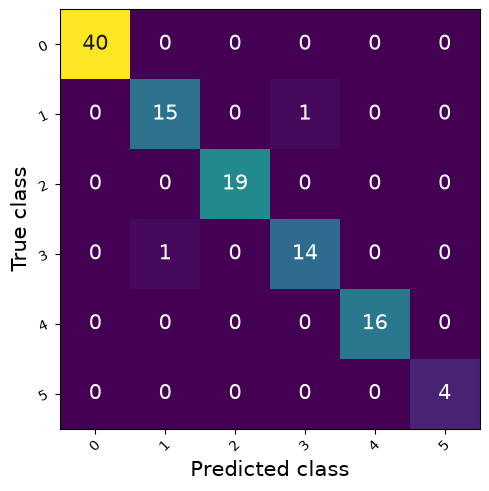

In [502]:
from torchmetrics.classification import MulticlassConfusionMatrix
from torchmetrics.utilities.plot import plot_confusion_matrix

cm = MulticlassConfusionMatrix(num_classes=6)
matrix = cm(test_pred, y_test)

plot_confusion_matrix(matrix)

### Model Dışarı Çıkarma

In [503]:
from pathlib import Path

MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True, exist_ok=True)

MODEL_NAME = "dermatology_classification_model.pth"
MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME

torch.save(obj=model.state_dict(), f=MODEL_SAVE_PATH)